In [1]:
# Reading cleaned data from github link
import pandas as pd
customers   = pd.read_parquet("https://raw.githubusercontent.com/FarahHossamEldin/E-Commerce-Customer-Value-and-Purchase-Prediction-/main/data/processed/parquet/olist_customers_dataset.parquet")
order_items = pd.read_parquet("https://raw.githubusercontent.com/FarahHossamEldin/E-Commerce-Customer-Value-and-Purchase-Prediction-/main/data/processed/parquet/olist_order_items_dataset.parquet")
payments    = pd.read_parquet("https://raw.githubusercontent.com/FarahHossamEldin/E-Commerce-Customer-Value-and-Purchase-Prediction-/main/data/processed/parquet/olist_order_payments_dataset.parquet")
reviews     = pd.read_parquet("https://raw.githubusercontent.com/FarahHossamEldin/E-Commerce-Customer-Value-and-Purchase-Prediction-/main/data/processed/parquet/olist_order_reviews_dataset.parquet")
orders      = pd.read_parquet("https://raw.githubusercontent.com/FarahHossamEldin/E-Commerce-Customer-Value-and-Purchase-Prediction-/main/data/processed/parquet/olist_orders_dataset.parquet")

# **1. Feature Engineering**

In [2]:
# Check the number of unique customers, customer IDs, and orders to understand the relationships between the datasets
print('Customers unique ID:', customers['customer_unique_id'].nunique())
print('Customer IDs:', customers['customer_id'].nunique())
print('Orders:', orders['order_id'].nunique())
print('Customers in orders:', orders['customer_id'].nunique())

Customers unique ID: 96096
Customer IDs: 99441
Orders: 99441
Customers in orders: 99441


**Each row represents one order, linked to its corresponding unique customer.**

In [3]:
# Creating "Order" dataframe through merging tables
orders_customers = orders.merge(customers[['customer_id', 'customer_unique_id']],
    on='customer_id',how='left')

In [4]:
# Validate the merge by checking the total number of rows, missing customer IDs, and unique customers
print('Rows:', len(orders_customers))
print('Missing customers:', orders_customers['customer_unique_id'].isna().sum())
print('Unique customers:', orders_customers['customer_unique_id'].nunique())

Rows: 99441
Missing customers: 0
Unique customers: 96096


In [5]:
# Check the distribution of orders across different statuses
orders_customers['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [6]:
# Identify the start and end dates of the order data
print(orders_customers['order_purchase_timestamp'].min())
print(orders_customers['order_purchase_timestamp'].max())

2016-09-04 21:15:19
2018-10-17 17:30:18


In [7]:
# Filter delivered orders for customer purchase behavior analysis
delivered_orders = orders_customers[orders_customers['order_status'] == 'delivered'].copy()
delivered_orders['order_status'].value_counts()

,count
order_status,
delivered,96478


**Check: how many delivered orders does each customer have?** (most customers buy only once, so customers who come back are rare)

In [8]:
# Calculate the total number of delivered orders per customer.
customer_purchase_count = (
    delivered_orders.groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index(name='purchase_count'))
customer_purchase_count.head()

,customer_unique_id,purchase_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [9]:
# Analyze the distribution of purchase frequency across customers.
customer_purchase_count['purchase_count'].value_counts().sort_index()

,count
purchase_count,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


**Add the order value and review score to each delivered order.**

In [10]:
# Total amount paid for each order (one order can have more than one payment)
order_value = payments.groupby('order_id')['payment_value'].sum().reset_index(name='order_value')

# Add the order value to delivered orders
delivered_orders = delivered_orders.merge(order_value, on='order_id', how='left')
print('Orders without payment:', delivered_orders['order_value'].isna().sum())

Orders without payment: 1


In [11]:
# Average review score for each order (some orders have more than one review)
order_review = reviews.groupby('order_id')['review_score'].mean().reset_index()

# Add the review score to delivered orders
delivered_orders = delivered_orders.merge(order_review, on='order_id', how='left')
print('Orders without review:', delivered_orders['review_score'].isna().sum())

Orders without review: 646


# **2. Modelling: Repeat Purchase Prediction**
**Goal:** predict whether a first-time customer will make another purchase within the next 90 days.

**When is the prediction made?** Right after the first order is **delivered and reviewed**.
At that moment we already know the delivery time, if the order was late, and the review score,
so these features are allowed (they use only information about the first order, nothing from the future).

**Step 1: Take the first order of each customer and check if they bought again within 90 days (this is the target).**

In [12]:
# Sort each customer's orders from oldest to newest
delivered_orders = delivered_orders.sort_values(['customer_unique_id', 'order_purchase_timestamp'])

# Give each order a number: 1 = first order, 2 = second order, ...
delivered_orders['order_number'] = delivered_orders.groupby('customer_unique_id').cumcount() + 1

# Keep only the first order of each customer
first_orders = delivered_orders[delivered_orders['order_number'] == 1].copy()

# Date of the second order (empty if the customer never bought again)
second_orders = delivered_orders[delivered_orders['order_number'] == 2][['customer_unique_id', 'order_purchase_timestamp']]
second_orders = second_orders.rename(columns={'order_purchase_timestamp': 'second_purchase'})
first_orders = first_orders.merge(second_orders, on='customer_unique_id', how='left')

# Days between the first and the second order
first_orders['days_to_second'] = (first_orders['second_purchase'] - first_orders['order_purchase_timestamp']).dt.days

# Target: 1 if the customer bought again within 90 days, otherwise 0
# (days_to_second >= 1 because some orders are split into two orders at the same time -> not a real repeat)
first_orders['repeat_90d'] = ((first_orders['days_to_second'] >= 1) & (first_orders['days_to_second'] <= 90)).astype(int)

**Step 2: Keep only customers we can follow for a full 90 days after their first order.**

In [13]:
# Last date in the data, we use it as "today"
reference_date = delivered_orders['order_purchase_timestamp'].max()

# Customers who bought in the last 90 days of the data did not have 90 days to come back yet,
# so we can't know their real answer -> remove them
cutoff_date = reference_date - pd.Timedelta(days=90)
first_orders = first_orders[first_orders['order_purchase_timestamp'] <= cutoff_date]

print('Customers:', len(first_orders))
first_orders['repeat_90d'].value_counts()

Customers: 75320


,count
repeat_90d,
0,74384
1,936


**Step 3: Add features that describe the first order only (no information from later orders).**

In [14]:
# Number of items and shipping cost for each order
items_info = order_items.groupby('order_id').agg(
    items_count=('order_item_id', 'count'),
    freight_value=('freight_value', 'sum')
).reset_index()

# Number of payment installments for each order
installments = payments.groupby('order_id')['payment_installments'].max().reset_index()

# Payment type of each order (we take the first payment: payment_sequential = 1)
payment_type = payments[payments['payment_sequential'] == 1][['order_id', 'payment_type']]

first_orders = first_orders.merge(items_info, on='order_id', how='left')
first_orders = first_orders.merge(installments, on='order_id', how='left')
first_orders = first_orders.merge(payment_type, on='order_id', how='left')

# Delivery time in days, and whether the order arrived late
first_orders['delivery_days'] = (first_orders['order_delivered_customer_date'] - first_orders['order_purchase_timestamp']).dt.days
first_orders['is_late'] = (first_orders['order_delivered_customer_date'] > first_orders['order_estimated_delivery_date']).astype(int)

first_orders['payment_type'].value_counts()

,count
payment_type,
credit_card,58041
boleto,15302
voucher,1173
debit_card,746


In [15]:
# Numeric features of the first order
numeric_features = ['order_value', 'review_score', 'items_count', 'freight_value',
                    'payment_installments', 'delivery_days']

# Final table for Model 1: features of the first order + the target
# (we also keep the purchase date, only to split the data by time, it is not a feature)
model1_data = first_orders[['customer_unique_id', 'order_purchase_timestamp'] + numeric_features
                           + ['is_late', 'payment_type', 'repeat_90d']]

# One-hot encoding: turn payment_type (text) into 0/1 columns, one column for each payment type
model1_data = pd.get_dummies(model1_data, columns=['payment_type'], dtype=int)

# All features used by the models = numeric + is_late + the new payment columns
payment_columns = [col for col in model1_data.columns if col.startswith('payment_type_')]
model1_features = numeric_features + ['is_late'] + payment_columns
print('Features:', model1_features)

print(model1_data.isna().sum())
model1_data.head()

Features: ['order_value', 'review_score', 'items_count', 'freight_value', 'payment_installments', 'delivery_days', 'is_late', 'payment_type_boleto', 'payment_type_credit_card', 'payment_type_debit_card', 'payment_type_voucher']
customer_unique_id            0
order_purchase_timestamp      0
order_value                   1
review_score                535
items_count                   0
freight_value                 0
payment_installments          3
delivery_days                 2
is_late                       0
repeat_90d                    0
payment_type_boleto           0
payment_type_credit_card      0
payment_type_debit_card       0
payment_type_voucher          0
dtype: int64


,customer_unique_id,order_purchase_timestamp,order_value,review_score,items_count,freight_value,payment_installments,delivery_days,is_late,repeat_90d,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,141.90,5.0,1,12.00,8.0,6.0,0,0,0,1,0,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,27.19,4.0,1,8.29,1.0,3.0,0,0,0,1,0,0
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,86.22,3.0,1,17.22,8.0,25.0,0,0,0,1,0,0
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,43.62,4.0,1,17.63,4.0,20.0,0,0,0,1,0,0
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,196.89,5.0,1,16.89,6.0,13.0,0,0,0,1,0,0


**Correlation check: features vs each other and vs the target (before splitting the data).**

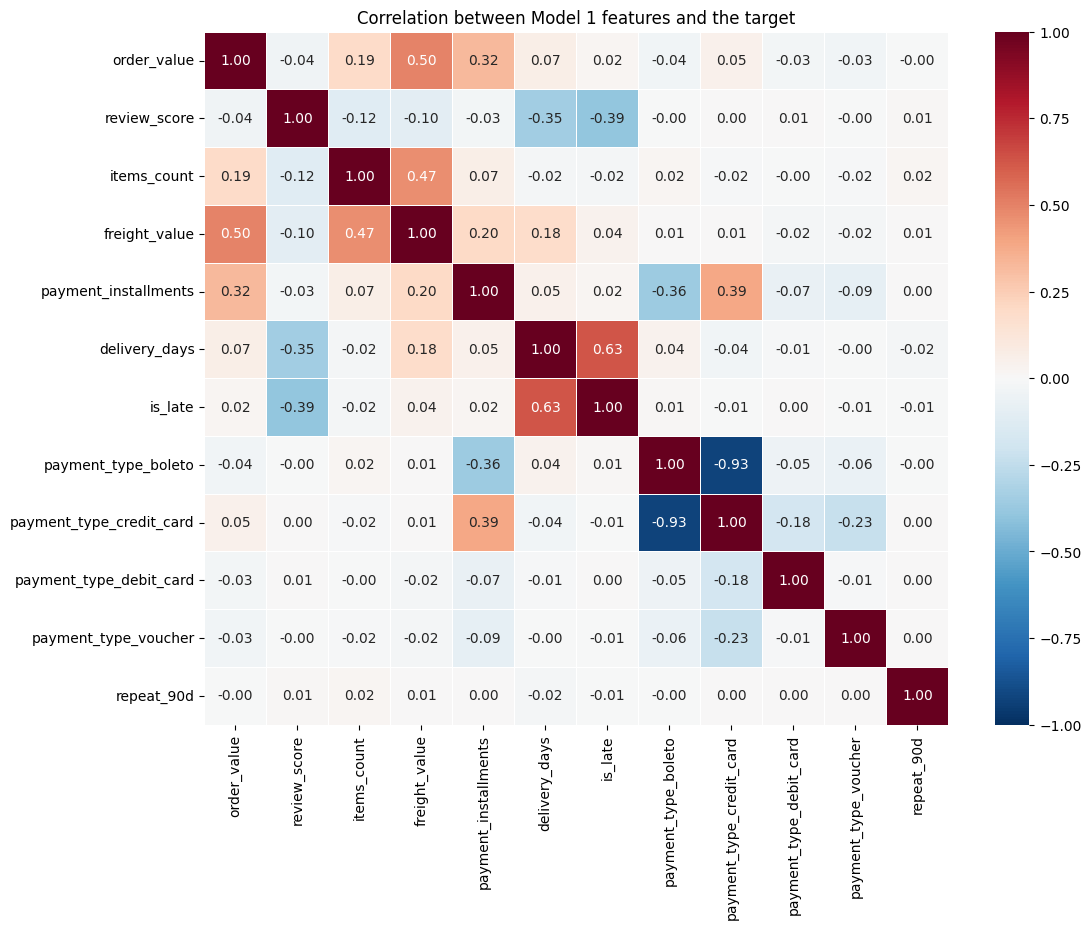

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation between the features and the target
corr = model1_data[model1_features + ['repeat_90d']].corr()

# Heatmap: red = positive, blue = negative, white = no correlation
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation between Model 1 features and the target')
plt.show()

**Step 4: Split the data by time (old customers = train, new customers = test), then fill missing values.**

In real life the model is trained on past customers and used on future customers,
so we train on the oldest 80% of customers and test on the newest 20%.

In [17]:
from sklearn.model_selection import train_test_split

# Sort the customers by the date of their first order (oldest first)
model1_data = model1_data.sort_values('order_purchase_timestamp')

# shuffle=False -> no random mixing: the first 80% (oldest) = train, the last 20% (newest) = test
train_data, test_data = train_test_split(model1_data, test_size=0.2, shuffle=False)

X_train = train_data[model1_features]
y_train = train_data['repeat_90d']
X_test = test_data[model1_features]
y_test = test_data['repeat_90d']

# Check the dates and the percentage of customers who came back in each part
print('Train:', X_train.shape, ' from', train_data['order_purchase_timestamp'].min().date(),
      'to', train_data['order_purchase_timestamp'].max().date())
print('Test: ', X_test.shape, ' from', test_data['order_purchase_timestamp'].min().date(),
      'to', test_data['order_purchase_timestamp'].max().date())
print('Came back (train):', round(y_train.mean() * 100, 2), '%')
print('Came back (test): ', round(y_test.mean() * 100, 2), '%')

# Fill missing values with the median of the train data (also used for the test data)
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)

Train: (60256, 11)  from 2016-09-15 to 2018-03-21
Test:  (15064, 11)  from 2018-03-21 to 2018-05-31
Came back (train): 1.21 %
Came back (test):  1.38 %


**Step 5: Model 1 - Logistic Regression pipeline (the simplest model, a linear baseline).**

We train the models from the simplest to the most complex: Logistic Regression -> Decision Tree -> Random Forest.

Each model is a **pipeline** = scaling + the model. The scaling is learned from the train data only,
and it is saved together with the model, so it is easy to deploy.

Accuracy is misleading here (predicting 0 for everyone gives ~98% accuracy), so we focus on recall and precision of class 1.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

# Pipeline = scaling (mean = 0, std = 1) + the model
# class_weight='balanced' gives more importance to the few customers who came back
# max_iter=1000 gives the model enough steps to finish training
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])

# The values we want to try ('model__' means: parameter of the 'model' step)
# C controls how simple the model is: small C = simpler model
lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10]
}

# GridSearchCV tries every combination using 5-fold cross validation on the train data
# scoring='f1' -> pick the combination that is best at finding customers who come back (class 1)
lr_grid = GridSearchCV(lr_pipeline, lr_param_grid, cv=5, scoring='f1', n_jobs=-1)
lr_grid.fit(X_train, y_train)

print('Best parameters:', lr_grid.best_params_)

# Final Logistic Regression pipeline, evaluated on the test data
# Predict 0 (won't come back) or 1 (will come back) for the test customers
lr_model = lr_grid.best_estimator_
lr_pred = lr_model.predict(X_test)

print(confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

Best parameters: {'model__C': 0.1}
[[6583 8273]
 [  80  128]]
              precision    recall  f1-score   support

           0       0.99      0.44      0.61     14856
           1       0.02      0.62      0.03       208

    accuracy                           0.45     15064
   macro avg       0.50      0.53      0.32     15064
weighted avg       0.97      0.45      0.60     15064



**Step 6: Model 2 - Decision Tree pipeline.**

In [19]:
from sklearn.tree import DecisionTreeClassifier

# Trees don't need scaling, but we keep the same pipeline steps for all 3 models
# so they are all used the same way in deployment
tree_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

tree_param_grid = {
    'model__max_depth': [3, 5, 8, 12],
    'model__min_samples_leaf': [1, 10, 50]
}

tree_grid = GridSearchCV(tree_pipeline, tree_param_grid, cv=5, scoring='f1', n_jobs=-1)
tree_grid.fit(X_train, y_train)

print('Best parameters:', tree_grid.best_params_)

# Final Decision Tree pipeline, evaluated on the test data
tree_model = tree_grid.best_estimator_
tree_pred = tree_model.predict(X_test)

print(confusion_matrix(y_test, tree_pred))
print(classification_report(y_test, tree_pred))

Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 10}
[[6892 7964]
 [  91  117]]
              precision    recall  f1-score   support

           0       0.99      0.46      0.63     14856
           1       0.01      0.56      0.03       208

    accuracy                           0.47     15064
   macro avg       0.50      0.51      0.33     15064
weighted avg       0.97      0.47      0.62     15064



**Step 7: Model 3 - Random Forest pipeline.**

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 8, 12],
    'model__min_samples_leaf': [1, 10]
}

rf_grid = GridSearchCV(rf_pipeline, rf_param_grid, cv=5, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print('Best parameters:', rf_grid.best_params_)

# Final Random Forest pipeline, evaluated on the test data
rf_model = rf_grid.best_estimator_
rf_pred = rf_model.predict(X_test)

print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
[[10351  4505]
 [  132    76]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82     14856
           1       0.02      0.37      0.03       208

    accuracy                           0.69     15064
   macro avg       0.50      0.53      0.42     15064
weighted avg       0.97      0.69      0.81     15064



In [21]:
# Which features helped the Random Forest the most
importance = pd.Series(rf_model.named_steps['model'].feature_importances_, index=model1_features)
importance.sort_values(ascending=False)

,0
order_value,0.241253
delivery_days,0.223685
freight_value,0.213328
review_score,0.086124
payment_installments,0.081225
items_count,0.079373
is_late,0.023846
payment_type_boleto,0.017885
payment_type_voucher,0.016355
payment_type_credit_card,0.011663


**Step 8: Compare the three models (class 1 = customers who came back, on the test data).**

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

predictions = {
    'Logistic Regression': lr_pred,
    'Decision Tree': tree_pred,
    'Random Forest': rf_pred
}

results = []
for name, pred in predictions.items():
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

results = pd.DataFrame(results)
results

,Model,Precision,Recall,F1
0,Logistic Regression,0.015236,0.615385,0.029736
1,Decision Tree,0.014478,0.562500,0.028230
2,Random Forest,0.016590,0.365385,0.031739


**Step 9: Save each pipeline to a file for deployment.**
We also save the train median (to fill missing values) and the list of feature columns,
because the deployed app needs them to prepare a new customer's data the same way.

In [23]:
import joblib

joblib.dump(lr_model, 'lr_pipeline.pkl')
joblib.dump(tree_model, 'tree_pipeline.pkl')
joblib.dump(rf_model, 'rf_pipeline.pkl')
joblib.dump(train_median, 'train_median.pkl')
joblib.dump(model1_features, 'model1_features.pkl')
print('Saved: lr_pipeline.pkl, tree_pipeline.pkl, rf_pipeline.pkl, train_median.pkl, model1_features.pkl')

Saved: lr_pipeline.pkl, tree_pipeline.pkl, rf_pipeline.pkl, train_median.pkl, model1_features.pkl
